# TCGA bei ε = 0,1 Nat

Die historischen Verläufe umfassen 27 Kombinationen aus Gruppe, Split-Seed und Trainings-Seed. Der neue Probelauf mit patientengetrennten Splits wird gesondert ausgewertet.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/core_real_final").is_dir())
GRID = ROOT / "results/guarded_varix_eps0_1_seedgrid_2026-11-22"
PILOT = ROOT / "results/guarded_varix_patient_pilot_2026-11-23"
GROUPS = ["all_classes", "ontix_standard", "weak_signal_lowvar"]

def read_run(path):
    rows = [json.loads(line) for line in (path / "collapse_history.jsonl").read_text().splitlines() if line.strip()]
    frame = pd.DataFrame(rows)
    manifest = json.loads((path / "data_manifest.json").read_text())
    frame["group"] = manifest["group"]
    frame["split_seed"] = manifest["split_seed"]
    frame["train_seed"] = manifest["train_seed"]
    frame["run"] = path.name
    return frame

reported = json.loads((GRID / "beta_results.json").read_text())["tcga"]
run_paths = [ROOT / row["run_dir"] for group in GROUPS for row in reported[group]]
assert len(set(run_paths)) == len(run_paths) == 27
history = pd.concat([read_run(path) for path in run_paths], ignore_index=True)
print(f"{len(run_paths)} Läufe")
history.groupby("group").agg(runs=("run", "nunique"), epochs=("epoch_number", "count"))

27 Läufe


,runs,epochs
group,,
all_classes,9,3367
ontix_standard,9,3585
weak_signal_lowvar,9,4071


## Gesamt-KL und beta über Epochen

Feine Linien sind einzelne Läufe. Dicke Linien zeigen den Gruppenmedian. Rot markiert den ersten Lucas-Vollkollaps.

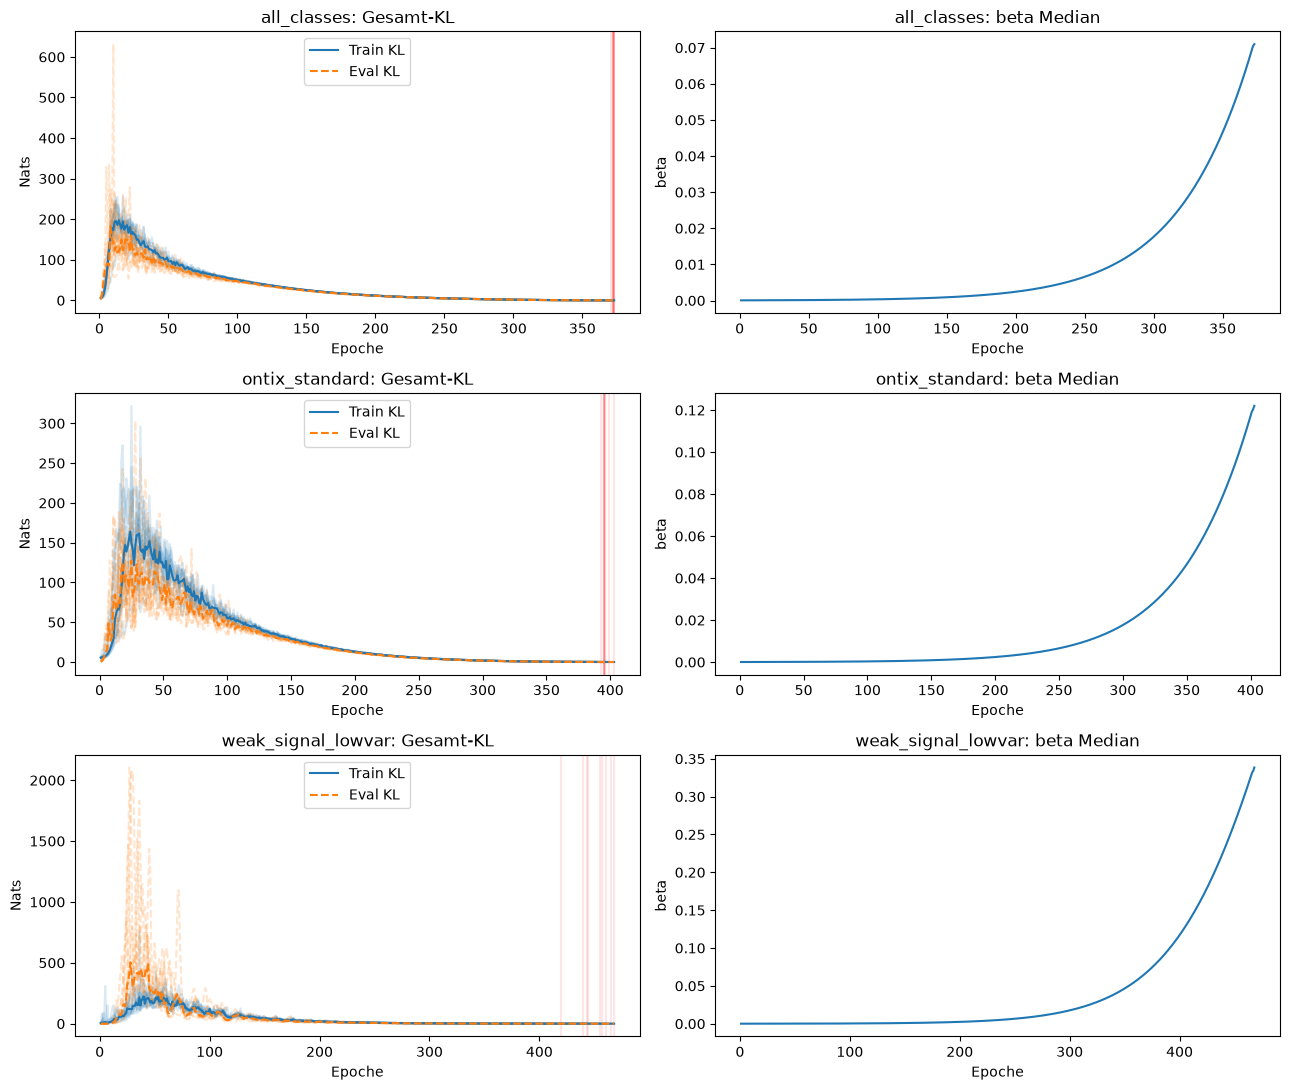

In [2]:
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for row, group in enumerate(GROUPS):
    part = history[history.group == group]
    for _, run in part.groupby("run"):
        run = run.sort_values("epoch_number")
        axes[row, 0].plot(run.epoch_number, run.R_train_nats, color="tab:blue", alpha=.16)
        axes[row, 0].plot(run.epoch_number, run.R_train_eval_nats, color="tab:orange", alpha=.2, linestyle="--")
        collapse = run[run.lucas_full_collapse_train_eval == True]
        if len(collapse):
            axes[row, 0].axvline(collapse.iloc[0].epoch_number, color="red", alpha=.1)
    med = part.groupby("epoch_number")[["R_train_nats", "R_train_eval_nats"]].median()
    axes[row, 0].plot(med.index, med.R_train_nats, color="tab:blue", label="Train KL")
    axes[row, 0].plot(med.index, med.R_train_eval_nats, color="tab:orange", linestyle="--", label="Eval KL")
    axes[row, 0].set(title=group + ": Gesamt-KL", xlabel="Epoche", ylabel="Nats")
    axes[row, 0].legend()
    beta = part.groupby("epoch_number").beta_batch_last.median()
    axes[row, 1].plot(beta.index, beta.values)
    axes[row, 1].set(title=group + ": beta Median", xlabel="Epoche", ylabel="beta")
plt.tight_layout()

## KL je latenter Dimension

Median der mittleren Trainings-KL über Läufe, getrennt nach Dimension.

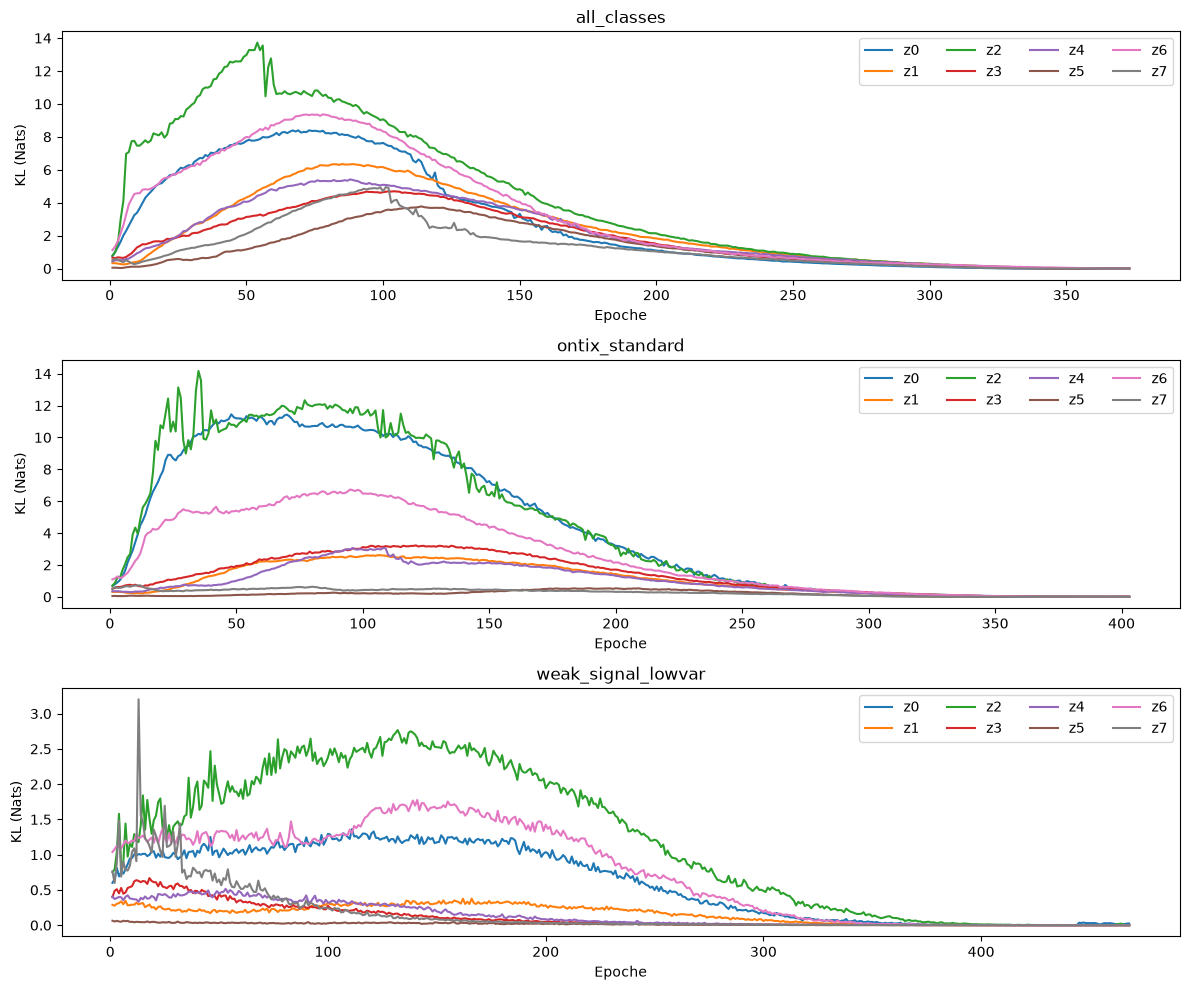

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, group in zip(axes, GROUPS):
    part = history[history.group == group]
    matrix = np.stack(part.train_R_j_nats.to_numpy())
    rates = pd.DataFrame(matrix, index=part.epoch_number).groupby(level=0).median()
    for dim in rates.columns:
        ax.plot(rates.index, rates[dim], label=f"z{dim}")
    ax.set(title=group, xlabel="Epoche", ylabel="KL (Nats)")
    ax.legend(ncol=4)
plt.tight_layout()

## Lucas: Sample-Anteil mit KL mindestens epsilon

Je Dimension wird der Anteil der Samples gezeigt, deren KL >= epsilon ist. Ein Anteil über 1 Prozent bedeutet, dass diese Dimension nach dem Lucas-Kriterium aktiv bleibt.

Median Sample-Anteil KL >= epsilon, PI-Ende


,z0,z1,z2,z3,z4,z5,z6,z7
group,,,,,,,,
all_classes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ontix_standard,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
weak_signal_lowvar,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


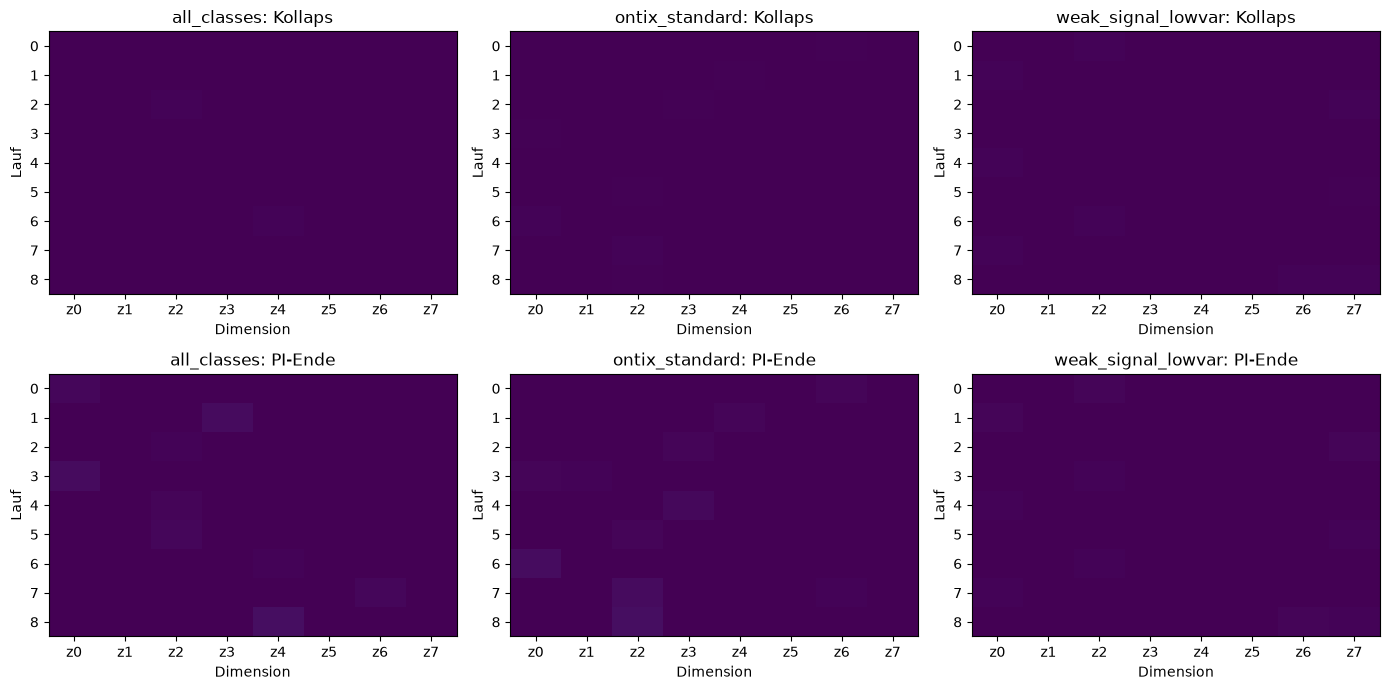

In [4]:
def lucas_rows(condition):
    selected = history[condition]
    output = []
    for _, entry in selected.iterrows():
        shares = np.asarray(entry.lucas_share_active_train_eval, dtype=float)
        output.append({"group": entry.group, "run": entry.run,
                       **{f"z{j}": value for j, value in enumerate(shares)}})
    return pd.DataFrame(output)

collapse = lucas_rows((history.phase == "annealing") & history.lucas_full_collapse_train_eval).drop_duplicates("run")
stable = lucas_rows((history.phase == "done") & (history.lucas_full_collapse_train_eval == False))
dims = [c for c in stable.columns if c.startswith("z")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, group in enumerate(GROUPS):
    for row, frame in enumerate((collapse, stable)):
        values = frame.loc[frame.group == group, dims].to_numpy()
        axes[row, col].imshow(values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
        axes[row, col].set(title=f"{group}: " + ("Kollaps" if row == 0 else "PI-Ende"),
                           xlabel="Dimension", ylabel="Lauf", xticks=range(len(dims)), xticklabels=dims)
plt.tight_layout()
print("Median Sample-Anteil KL >= epsilon, PI-Ende")
display(stable.groupby("group")[dims].median().round(4))

## Probelauf mit Patiententrennung

Die Rate ist die über Achsen summierte KL in Nat pro Probe. Die Distortion ist die mittlere quadratische Abweichung zwischen den skalierten Merkmalen und der Rekonstruktion aus dem Posterior-Mittelwert μ. Jede Probe und jedes Merkmal geht gleich gewichtet ein. Die Kurve verwendet die Trainingsproben im Eval-Modus. Sie zeigt das Annealing bis zum ersten Vollkollaps. Für die historischen 27 Läufe fehlt diese MSE.

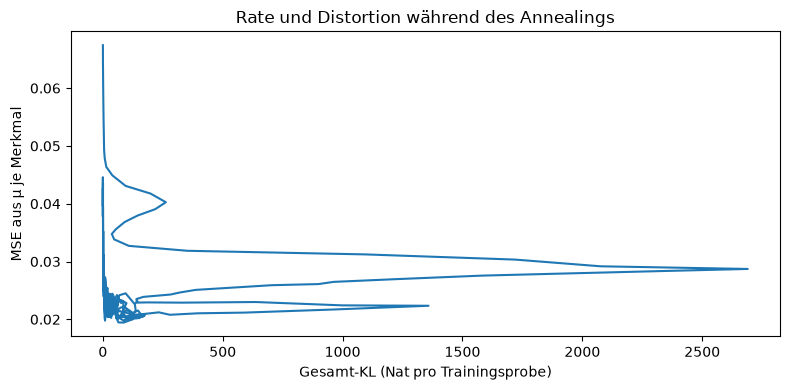

In [5]:
pilot_dir, = (PILOT / "beta_guard_vae").glob("tcga-weak_signal_lowvar-*")
pilot = read_run(pilot_dir)
annealing = pilot[pilot.phase == "annealing"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(annealing.R_train_eval_nats, annealing.mse_train_eval_mu)
ax.set(xlabel="Gesamt-KL (Nat pro Trainingsprobe)", ylabel="MSE aus μ je Merkmal",
       title="Rate und Distortion während des Annealings")
plt.tight_layout()

## Rekonstruktion und Klasseninformation an den Checkpoints

Alle drei Panels verwenden dieselben Validierungsproben pro Checkpoint. Die logistische Regression lernt auf Trainingsproben. Die AUROC für z ist der Mittelwert aus fünf Ziehungen. Das varianzgewichtete R² und die MSE verwenden die Rekonstruktion aus μ. Gleiche Epochennummern nach einem Rücksprung werden über den eindeutigen Snapshot-Pfad unterschieden.

,epoch_number,event,attempt,beta,valid_rate_nats,valid_mse_mu,valid_r2_weighted_mu,mu,sampled_z
0,447,annealing_collapse,0,0.253506,0.020715,0.040608,-1.715960,0.477011,0.459251
1,446,handover,0,0.249740,0.022901,0.041915,-1.803376,0.471264,0.459622
2,447,pi_collapse,0,0.248783,0.020721,0.040608,-1.715958,0.477011,0.459251
3,445,handover,1,0.246011,0.023782,0.042042,-1.811824,0.480905,0.459770
4,446,done,1,0.246011,0.022919,0.041915,-1.803378,0.471264,0.459622


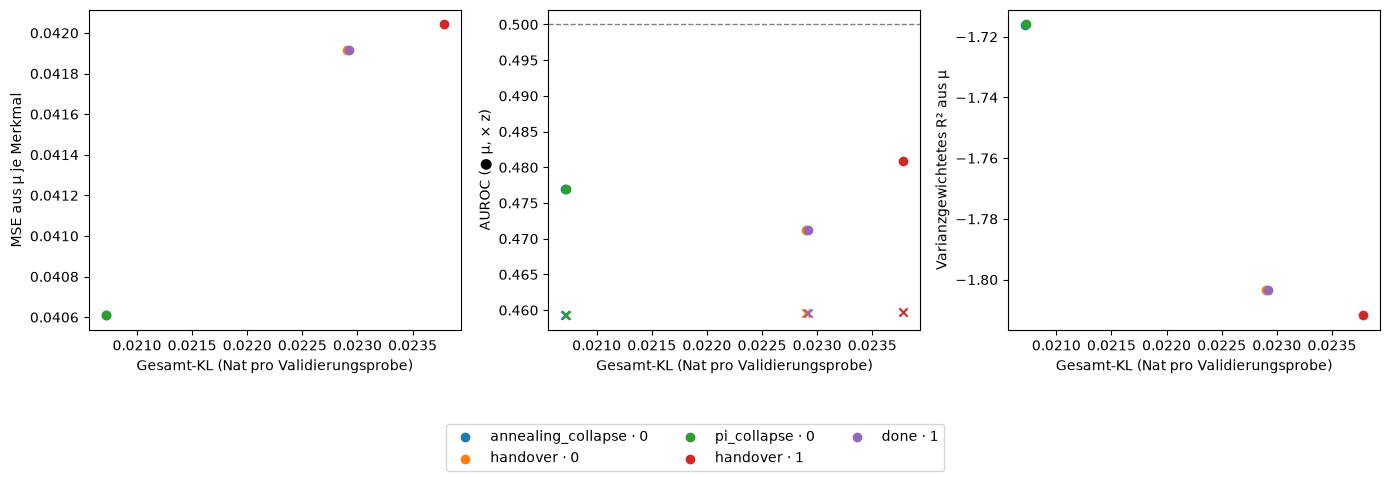

In [6]:
snapshots = pd.read_json(pilot_dir / "posterior_index.jsonl", lines=True)
auc = pd.read_csv(pilot_dir / "auroc.csv")
auc_by_snapshot = auc.groupby(["path", "representation"]).auroc_ovo.mean().unstack()
points = snapshots.merge(auc_by_snapshot, on="path", validate="one_to_one")
display(points[["epoch_number", "event", "attempt", "beta", "valid_rate_nats",
                "valid_mse_mu", "valid_r2_weighted_mu", "mu", "sampled_z"]])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True)
for checkpoint in points.itertuples():
    label = f"{checkpoint.event} · {checkpoint.attempt}"
    rate = checkpoint.valid_rate_nats
    dot = axes[0].scatter(rate, checkpoint.valid_mse_mu, label=label)
    color = dot.get_facecolor()[0]
    axes[1].scatter(rate, checkpoint.mu, color=color)
    axes[1].scatter(rate, checkpoint.sampled_z, marker="x", color=color)
    axes[2].scatter(rate, checkpoint.valid_r2_weighted_mu, color=color)
axes[1].axhline(0.5, linestyle="--", color="grey", linewidth=1)
for ax, label in zip(axes, ["MSE aus μ je Merkmal", "AUROC (● μ, × z)", "Varianzgewichtetes R² aus μ"]):
    ax.set(xlabel="Gesamt-KL (Nat pro Validierungsprobe)", ylabel=label)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3)
fig.tight_layout(rect=[0, .18, 1, 1])
fig.savefig(PILOT / "rate_distortion_auroc_r2.png", dpi=180, bbox_inches="tight")

## Tail- und Ausreißer-Check

Q99/Mittelwert zeigt, ob eine kleine Sample-Gruppe die obere Verteilungsspitze bildet. Das ist ein Hinweis auf einen schweren Tail, aber ohne Sample-IDs und Maxima kein Beleg für technische Ausreißer. Der zweite Teil sucht Patienten mit KL >= epsilon in exportierten Posterior-Dateien und läuft, sobald solche NPZ-Dateien vorhanden sind.

,runs,q99_mean_ratio_median,q99_mean_ratio_min,q99_mean_ratio_max,active_dims_median,largest_sample_share_median
group,,,,,,
all_classes,9,35.1039,30.2871,37.1568,1.0,0.0165
ontix_standard,9,28.1669,22.6507,32.8695,1.0,0.0156
weak_signal_lowvar,9,17.9240,9.8594,27.4829,1.0,0.0113


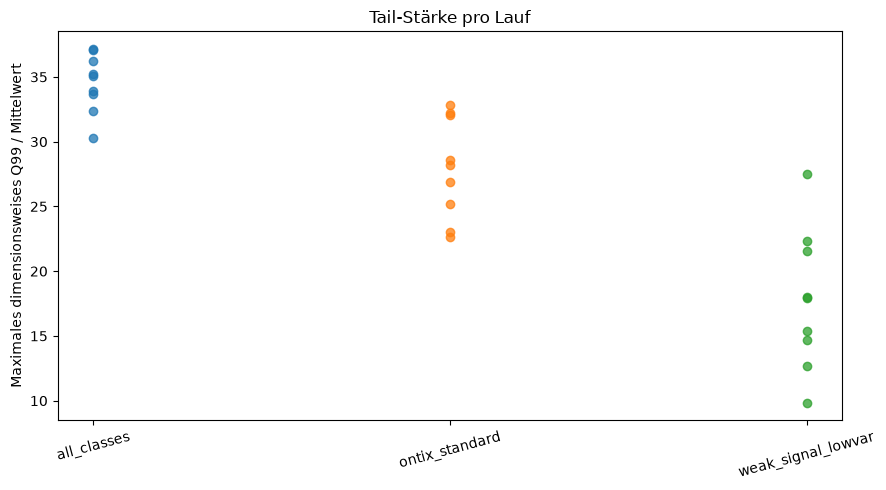

In [7]:
# Verteilungstail am Ende der kollapsfreien PI-Halteepoche
stable_rows = history[(history.phase == "done") & (history.lucas_full_collapse_train_eval == False)].copy()
tail_records = []
for _, entry in stable_rows.iterrows():
    means = np.asarray(entry.R_j_train_eval_nats, dtype=float)
    q99 = np.asarray(entry.lucas_q99_train_eval_nats, dtype=float)
    shares = np.asarray(entry.lucas_share_active_train_eval, dtype=float)
    ratio = np.divide(q99, means, out=np.full_like(q99, np.nan), where=means > 0)
    tail_records.append({
        "group": entry.group, "run": entry.run,
        "max_dimension_q99_over_mean": np.nanmax(ratio),
        "dimensions_with_share_over_1pct": int((shares > .01).sum()),
        "largest_sample_share_ge_epsilon": shares.max(),
        "max_dimension_q99_nats": q99.max(),
    })
tail = pd.DataFrame(tail_records)
display(tail.groupby("group").agg(
    runs=("run", "nunique"),
    q99_mean_ratio_median=("max_dimension_q99_over_mean", "median"),
    q99_mean_ratio_min=("max_dimension_q99_over_mean", "min"),
    q99_mean_ratio_max=("max_dimension_q99_over_mean", "max"),
    active_dims_median=("dimensions_with_share_over_1pct", "median"),
    largest_sample_share_median=("largest_sample_share_ge_epsilon", "median"),
).round(4))

fig, ax = plt.subplots(figsize=(9, 5))
for group in GROUPS:
    values = tail.loc[tail.group == group, "max_dimension_q99_over_mean"]
    ax.scatter([group] * len(values), values, alpha=.75)
ax.set(ylabel="Maximales dimensionsweises Q99 / Mittelwert",
       title="Tail-Stärke pro Lauf")
plt.xticks(rotation=15)
plt.tight_layout()

In [8]:
# Patientenliste, falls die Läufe Posterior-Snapshots enthalten
posterior_paths = sorted(path for run in run_paths for path in run.glob("posteriors/*.npz"))
if not posterior_paths:
    print("Keine Posterior-NPZ gefunden. Patienten-IDs und Max-KL sind für diese Läufe nicht gespeichert.")
else:
    import re
    patient_rows = []
    for path in posterior_paths:
        run_path = path.parent.parent
        manifest = json.loads((run_path / "data_manifest.json").read_text())
        with np.load(path) as data:
            split = "valid" if "valid_mu" in data else "train"
            mu = data[f"{split}_mu"].astype(np.float64)
            logvar = data[f"{split}_logvar"].astype(np.float64)
            ids = data[f"{split}_ids"].astype(str)
        kl = -0.5 * (1 + logvar - mu**2 - np.exp(logvar))
        epsilon = .1
        for dim in range(kl.shape[1]):
            selected = np.flatnonzero(kl[:, dim] >= epsilon)
            for index in selected:
                patient_rows.append({
                    "group": manifest["group"], "split_seed": manifest["split_seed"],
                    "train_seed": manifest["train_seed"], "epoch_file": path.name,
                    "sample_id": ids[index], "dimension": dim,
                    "kl_nats": kl[index, dim], "total_kl_nats": kl[index].sum(),
                })
    patient_outliers = pd.DataFrame(patient_rows)
    display(patient_outliers.sort_values("kl_nats", ascending=False).head(30))
    if len(patient_outliers):
        overlap = (patient_outliers.groupby(["group", "sample_id"]).size()
                   .rename("run_dimension_hits").sort_values(ascending=False).reset_index())
        display(overlap.head(30))

Keine Posterior-NPZ gefunden. Patienten-IDs und Max-KL sind für diese Läufe nicht gespeichert.


## Hält ControlVAE 50 Epochen durch?

Jede Tabellenzeile beschreibt einen Versuch nach einem Rücksprung. Die Haltezeit beginnt mit dem ersten PI-Update. Die Kollapsprüfung erfolgt jeweils am Epochenende auf den Trainingsproben im Eval-Modus. Ein stabilisiertes β wird erst nach 50 vollständig beobachteten Epochen ohne Vollkollaps angegeben.

In [9]:
hold_root = ROOT / "results/guarded_varix_hold50_pilot_2026-11-23/beta_guard_vae"
attempts = []
for summary_path in sorted(hold_root.glob("*/guard_summary.json")):
    run = read_run(summary_path.parent)
    held = run[run.state.eq("hold")]
    for attempt, rows in held.groupby("attempt", sort=False):
        last = rows.iloc[-1]
        attempts.append({
            "Gruppe": last.group, "Versuch": int(attempt) + 1,
            "PI-Epochen": len(rows),
            "Epochen ohne Vollkollaps": int((~rows.lucas_full_collapse_train_eval).sum()),
            "β am Ende": last.beta_batch_last,
            "β stabil über 50 Epochen": last.beta_batch_last if last.phase == "done" else np.nan,
        })
pd.DataFrame(attempts)

,Gruppe,Versuch,PI-Epochen,Epochen ohne Vollkollaps,β am Ende,β stabil über 50 Epochen
0,ontix_standard,1,1,0,0.110078,NaN
1,ontix_standard,2,2,1,0.106328,NaN
2,ontix_standard,3,3,2,0.104696,NaN
3,ontix_standard,4,4,3,0.101253,NaN
4,weak_signal_lowvar,1,1,0,0.248783,NaN
5,weak_signal_lowvar,2,2,1,0.246011,NaN
6,weak_signal_lowvar,3,3,2,0.242320,NaN
7,weak_signal_lowvar,4,4,3,0.238667,NaN
